# CH4-to-CO pathway index (bundled example)

What: a 1x4 (Antistellar/Morning/Substellar/Evening) pres-vs-latitude
slice figure showing the dominant CH4-to-CO reaction pathway at every
grid location, for HD 189733b at SAMPLE resolution, with quench-level
contours drawn on top.

This notebook runs out of the box - it reads the small dataset bundled
under `inputs/example_data/`, built by `scripts/generate_example_data.py`
from a real pipeline run rather than hand-written as a fixture, so no
completed pipeline run of your own is needed. Everything plotted is
loaded from `quenchpath merge-paths`' merged `.nc` (see
`quenchpath.stages.stage_06_merge_paths`/
`quenchpath.io.load_merged_paths`), not re-read from stage 05's
per-location JSON.

Why kinetics only: pathway/rate-network analysis has no
equilibrium-chemistry equivalent. `exp="equ"` is used in exactly one
place below - `tau_adv_qn`, see the overlay notes.

**To plot your own completed pipeline runs instead of this example, see
`docs/user_guide.md`.** This notebook is deliberately fixed to the
bundled example so it always reproduces the same figure.

## Overlays

Four independent toggles in the settings cell:

- `overlay_tau_adv_ls` / `overlay_tau_adv_qn` - the "quench level",
  where a pathway timescale crosses an advection timescale
  (tau_<conversion>/tau_adv = 1). Each draws *both* pathway
  quantities: net (whole-path-summed) and RLS (the single
  rate-limiting/bottleneck segment) - dashed/dashdot for ls, solid/
  dotted for qn. See
  `quenchpath.viz.quench_level_contour_panels()`'s own docstring for
  the linestyle convention. Each line is one call to
  `quenchpath.analysis.quench_level.quench_level()`, varying its
  `chem_kind` ("net"/"rls") and `adv_kind` ("ls"/"qn") arguments.
- `overlay_zahnle` - the *same* tau_adv paired against Zahnle & Marley
  (2014)'s literature quench timescale instead of a quenchpath-derived
  one, drawn in a distinct color. Locations outside their calibration
  envelope (T >= 2200 K, see `zahnle_marley_2014_invalid_mask()`) are
  hatched, keeping the comparison honest about where their formula is
  extrapolated rather than genuinely tested.
- `overlay_quench_region` - the CH4 quench *region* rather than another
  ratio=1 crossing: a fixed 1 e-folding band (`|ln(ratio)|<1`, the same
  convention `tau_adv_qn`'s own definition uses) around `ratio_net_qn`'s
  ratio=1 line, marking where quenchpath's "CH4->CO is net-favoured
  at/below the quench level" assumption can break down (see
  `quenchpath.analysis.k_test_over_k_eq`'s own module docstring).

Why `tau_adv_qn` comes from an `exp="equ"` run while everything else is
`exp="kin"`: it needs the equilibrium field's own mole-fraction
gradient, not a kinetics run's already-reaction-shaped one - see
`calc_and_save_adv_qn()`'s own docstring.

Why the Zahnle overlay needs no metallicity guard here: Zahnle & Marley
(2014) were only fit at m=1 (solar) and m=3, and this example's
HD 189733b run is solar ([M/H]=0, so m=1) - nothing is being
extrapolated on the metallicity axis.

In [1]:
import warnings

import numpy as np
import yaml

from quenchpath import io
from quenchpath.analysis.quench_level import (
    quench_level,
    quench_level_zahnle_ls,
    quench_level_zahnle_qn,
)
from quenchpath.analysis.zahnle_marley_2014 import zahnle_marley_2014_invalid_mask
from quenchpath.config import GridResolution, RunConfig, SpeciesConversion
from quenchpath.mypaths import path_to_example_data, path_to_planets_yaml
from quenchpath.viz import (
    pathway_index_contourf_kw,
    pathway_index_legend_handles,
    plot_field_slices,
    quench_level_contour_panels,
    representative_lon_indices,
)

warnings.filterwarnings("ignore", module="iris")

# What: row titles use inputs/run_metadata/planets.yaml's own
# display-name convention (e.g. "HAT-P-11b") verbatim, not $-wrapped.
# Why: matplotlib's mathtext renders a bare "-" as a spaced minus sign
# ("HAT − P − 11b"), not a hyphen, so plain text is what actually looks
# right here - mathtext.default="regular" (set in quenchpath.viz)
# already makes $...$ content match this same upright style, so
# there's no rendering difference to gain by wrapping it anyway.
with open(path_to_planets_yaml) as f:
    PLANET_NAMES = {k: v["tex"] for k, v in yaml.safe_load(f).items()}

# What: $-wrapped mathtext form of each species SpeciesConversion can
# name, for plain text (e.g. the pathway-index colorbar label).
# Why: CH4 needs the subscript wrapping every other figure in this
# codebase uses ($CH_4$); CO doesn't need any special formatting.
_SPECIES_TEX = {"CH4": r"$CH_{4}$", "CO": "CO"}

In [2]:
# What: fixed to the one run bundled in inputs/example_data/ -
# HD 189733b, kinetics, SAMPLE resolution, CH4-to-CO.
# Why fixed rather than configurable: this notebook is the package's own
# worked example, so it should always reproduce the same figure from
# data that ships with it. Plotting your own completed runs is a
# separate job - see docs/user_guide.md.
cfg = RunConfig(planet="hd189733b", exp="kin")
grid_resolution = GridResolution.SAMPLE
conversion = SpeciesConversion.CH4_CO
base_dir = path_to_example_data

# Quench-level overlays - see this notebook's own markdown intro. All
# four work against the bundled example; turn any of them off to see
# the pathway-index field on its own.
overlay_tau_adv_ls = True
overlay_tau_adv_qn = True
overlay_zahnle = True
overlay_quench_region = True

# This run's own [M/H] dex -> Zahnle & Marley's linear m. [M/H]=0 here,
# so m=1 - one of their two calibrated values (see the intro).
zahnle_m = 10 ** float(cfg.mdh)

In [3]:
# What: the figure's row title is the plain display name, with this
# run's metallicity reported in the printed line below instead.
# Why not both in the title: row 0's own loc="left" row title and the
# loc="right" "Antistellar" column title share the first panel's axes,
# and "HD 189733b ([M/H]=0)" is long enough to visibly collide with it
# (see plot_field_slices()'s own lon_titles parameter, which exists for
# this same collision).
run_title = PLANET_NAMES.get(cfg.planet, cfg.planet)

(
    temp_cube,
    pres_cube,
    path_index_cube,
    _net_rate_inv_cube,
    _max_rate_inv_cube,
    path_index_map,
) = io.load_merged_paths(cfg, grid_resolution, conversion=conversion, base_dir=base_dir)
n_indices = len(path_index_map)
print(
    f"{run_title} ([M/H]={cfg.mdh})/{cfg.exp} "
    f"({grid_resolution.value} resolution, {conversion.label}): "
    f"{path_index_cube.data.size} locations, {n_indices} known pathways"
)

# From this run's own longitude grid, not assumed - see
# representative_lon_indices()'s own docstring.
lon_idx = representative_lon_indices(path_index_cube.coord("longitude").points)

# Both pathway quantities (net, RLS) are drawn for whichever tau_adv
# kind(s) are toggled on - see quench_level_contour_panels()'s own
# docstring for the linestyle convention distinguishing all 4 (plus the
# 2 more overlay_zahnle adds).
ratio_net_ls = ratio_rls_ls = ratio_zahnle_ls = None
if overlay_tau_adv_ls:
    ratio_net_ls = quench_level(
        cfg, grid_resolution, "net", "ls", conversion=conversion, base_dir=base_dir
    ).data
    ratio_rls_ls = quench_level(
        cfg, grid_resolution, "rls", "ls", conversion=conversion, base_dir=base_dir
    ).data
    if overlay_zahnle:
        ratio_zahnle_ls = quench_level_zahnle_ls(
            cfg, pres_cube, temp_cube, m=zahnle_m, base_dir=base_dir
        ).data

ratio_net_qn = ratio_rls_qn = ratio_zahnle_qn = None
region_bounds = []
if overlay_tau_adv_qn:
    ratio_net_qn = quench_level(
        cfg, grid_resolution, "net", "qn", conversion=conversion, base_dir=base_dir
    ).data
    ratio_rls_qn = quench_level(
        cfg, grid_resolution, "rls", "qn", conversion=conversion, base_dir=base_dir
    ).data
    if overlay_zahnle:
        ratio_zahnle_qn = quench_level_zahnle_qn(
            cfg, pres_cube, temp_cube, m=zahnle_m, conversion=conversion, base_dir=base_dir
        ).data
    if overlay_quench_region:
        # What: a fixed 1 e-folding band on the same ratio_net_qn array
        # quench_level_contour_panels()'s own ratio=1 line already
        # draws. low/high are exp(-bound)/exp(bound).
        # Why exp(): drawn on the *linear* ratio array, not a log one,
        # so the contour lines land at the right ratio value.
        # Why CH4-specific: this band is only meaningful for the
        # CH4-to-CO conversion, which is what this notebook plots.
        region_bounds.append(
            (
                ratio_net_qn,
                np.exp(-1.0),
                np.exp(1.0),
                "CH4 quench region (1 $e$-fold)",
                "dotted",
                "tab:purple",
            )
        )

# Passing conversion= lets quench_level_contour_panels() build its own
# correct "CH4-to-CO" legend labels - no hand-built *_label overrides.
contour_panels, legend = quench_level_contour_panels(
    lon_idx,
    ratio_net_ls=ratio_net_ls,
    ratio_net_qn=ratio_net_qn,
    ratio_rls_ls=ratio_rls_ls,
    ratio_rls_qn=ratio_rls_qn,
    ratio_zahnle_ls=ratio_zahnle_ls,
    ratio_zahnle_qn=ratio_zahnle_qn,
    conversion=conversion,
    region_bounds=region_bounds,
)

hatch_panels = None
if ratio_zahnle_ls is not None or ratio_zahnle_qn is not None:
    # What: where Zahnle & Marley's own calibration envelope doesn't
    # cover this location (T >= 2200 K) - a hatched overlay on the
    # pathway-index panel itself, on the field's own true local
    # (level, lat) grid.
    # Why that grid: matches pathway_index_row()'s own panel_data
    # slicing below, and the contour lines default to it too.
    invalid_mask = zahnle_marley_2014_invalid_mask(temp_cube).data
    hatch_panels = [invalid_mask[..., lo] for lo in lon_idx]

HD 189733b ([M/H]=0)/kin (sample resolution, CH4-to-CO): 4896 locations, 6 known pathways


In [4]:
def pathway_index_row(_cfg):
    """This row's (lats, per-column pressures, per-column panel data).

    `_cfg` is unused - there's only one run here; plot_field_slices()
    passes it because the same hook serves its multi-run layout too.
    """
    lats = path_index_cube.coord("latitude").points
    panel_data = [path_index_cube.data[..., lo] for lo in lon_idx]
    # pres_mode="local" - each column's own true local pressure
    # (level, lat), not a shared 1D profile - see
    # quenchpath.viz.slice_panel_coords()'s own docstring. Also reused
    # as the contour lines' own default coordinate (see
    # plot_field_slices() below - no get_contour_coords needed).
    pres_cols = [pres_cube.data[..., lo] for lo in lon_idx]
    return lats, pres_cols, panel_data

Saved outputs/results/plots/slices/sample/slices_hd189733b_mdh0_tK1_sample_ch4_co.png


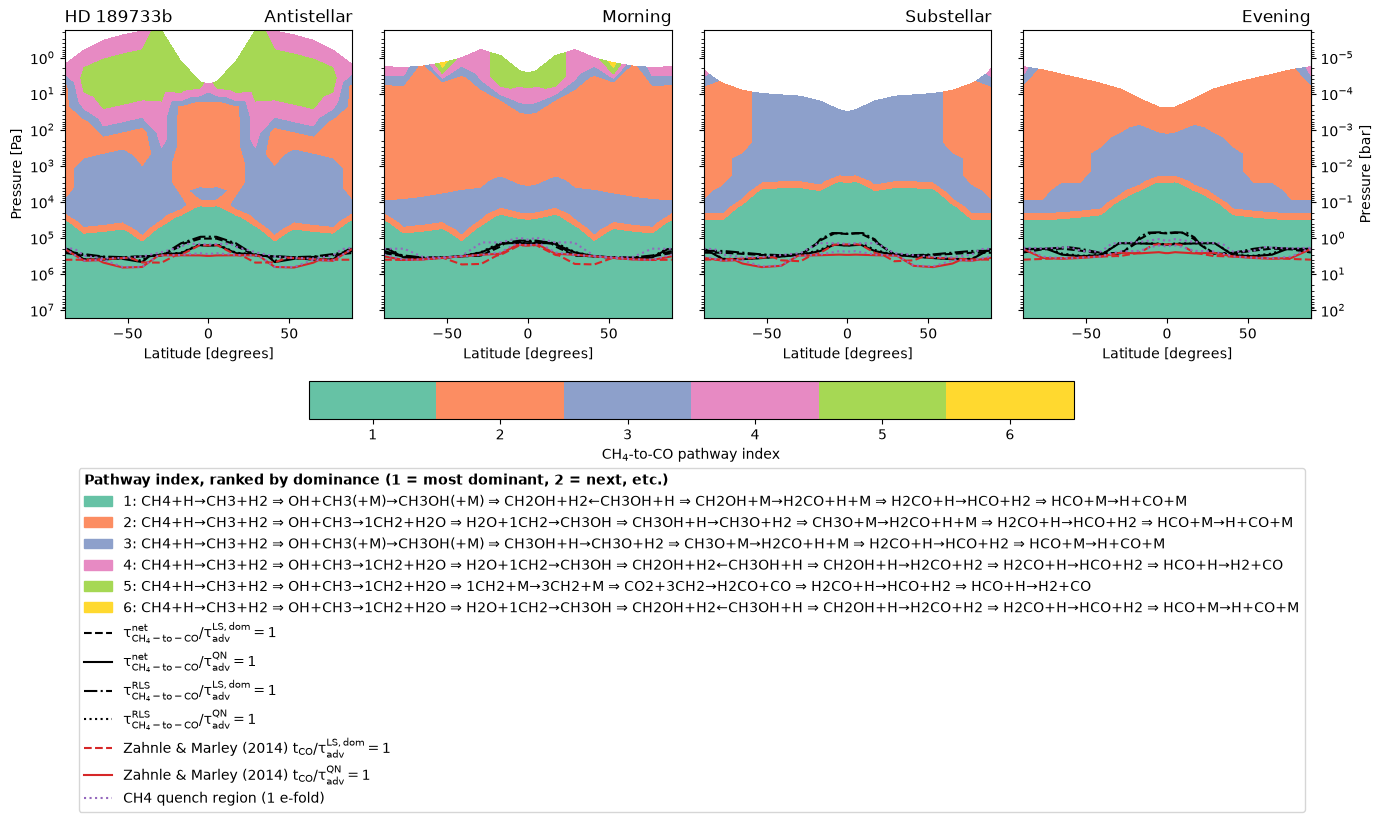

In [5]:
pathway_index_label = (
    f"{_SPECIES_TEX[conversion.source]}-to-{_SPECIES_TEX[conversion.target]} pathway index"
)
kw, cbar_ticks = pathway_index_contourf_kw(n_indices)
# Assigned rather than left as a bare expression: matplotlib's inline
# backend already displays the figure, so returning it as well would
# render the same figure twice in this notebook.
fig = plot_field_slices(
    [cfg],
    pathway_index_row,
    kw,
    pathway_index_label,
    f"slices/{grid_resolution.value}/slices_{cfg.planet}_mdh{cfg.mdh}_tK{cfg.tK}"
    f"_{grid_resolution.value}_{conversion.source.lower()}_{conversion.target.lower()}",
    get_contour_panels=lambda _c: contour_panels,
    get_hatch_panels=lambda _c: hatch_panels,
    contour_legend=legend,
    extra_legend_handles=pathway_index_legend_handles(path_index_map),
    legend_title="Pathway index, ranked by dominance (1 = most dominant, 2 = next, etc.)",
    cbar_ticks=cbar_ticks,
    ptype="contourf",
    planet_names={cfg: run_title},
    pres_mode="local",  # see docs/user_guide.md's "Plotting" section
    # What: no figsize= override needed.
    # Why: plot_field_slices()'s own save_figure() uses
    # bbox_inches="tight", which keeps row/column titles on-canvas
    # even once the combined legend grows large (see save_figure()'s
    # own docstring).
)